# 02 — Diagramme de Van Heerden, bifurcations et dimensionnement de l'enveloppe (S1-C03, S1-C04)

On trace la chaleur générée $Q_{gen}(T)$ et la chaleur évacuée $Q_{\acute{e}vac}(T)$ à l'état quasi-stationnaire en $C_A$ :

$$Q_{gen}(T)=(-\Delta H_r)\,k(T)\,C_A(T)\,V,\qquad
Q_{\acute{e}vac}(T)=F\rho C_p(T-T_{in}) + UA\,(T-T_c)$$

Un état stationnaire est une intersection ; il est **stable** si $dQ_{\acute{e}vac}/dT > dQ_{gen}/dT$ (critère de Van Heerden).

In [1]:
import sys, json
sys.path.insert(0, ".")
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path
from scipy.integrate import solve_ivp

from cstr_model import (Params, Inputs, rhs, arrhenius, UA_eff, steady_states_level1,
                        jacobian_level1, R_GAS, p_sat_water, relief_heat)
from presets_py import seborg, propylene_oxide
from pid_sim import (Pid, closed_loop, linearize, steady_state_level2, closed_loop_spectral_abscissa,
                     search_gains, max_recoverable_perturbation, step_metrics)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
GOLDEN = Path("..") / "tests" / "golden"


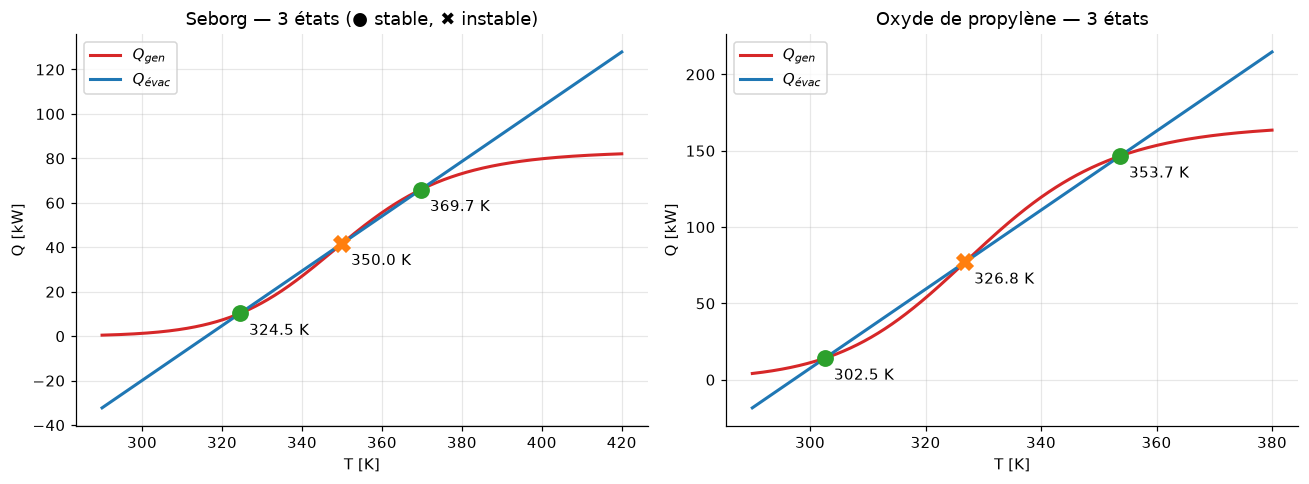

In [2]:
def qgen(T, p):
    D = p.F / p.V
    ca = D * p.CAin / (D + arrhenius(T, p.k0, p.EaR))
    return -p.dHr * arrhenius(T, p.k0, p.EaR) * ca * p.V

def qrem(T, p, Tc=None, UA=None):
    Tc = p.Tc if Tc is None else Tc
    UA = UA_eff(p) if UA is None else UA
    return p.F * p.rho * p.cp * (T - p.Tin) + UA * (T - Tc)

def vh_plot(ax, p, title, T_range):
    T = np.linspace(*T_range, 600)
    ax.plot(T, [qgen(t, p) / 1e3 for t in T], "tab:red", lw=2, label="$Q_{gen}$")
    ax.plot(T, [qrem(t, p) / 1e3 for t in T], "tab:blue", lw=2, label="$Q_{évac}$")
    for ca, Ts in steady_states_level1(p):
        slope_gen = (qgen(Ts + 1e-3, p) - qgen(Ts - 1e-3, p)) / 2e-3
        slope_rem = (qrem(Ts + 1e-3, p) - qrem(Ts - 1e-3, p)) / 2e-3
        stable = slope_rem > slope_gen
        ax.plot(Ts, qgen(Ts, p) / 1e3, "o" if stable else "X", ms=10,
                color="tab:green" if stable else "tab:orange")
        ax.annotate(f"{Ts:.1f} K", (Ts, qgen(Ts, p) / 1e3), textcoords="offset points", xytext=(6, -14))
    ax.set(title=title, xlabel="T [K]", ylabel="Q [kW]"); ax.legend()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
vh_plot(axes[0], seborg().with_(level=1), "Seborg — 3 états (● stable, ✖ instable)", (290, 420))
vh_plot(axes[1], propylene_oxide().with_(level=1), "Oxyde de propylène — 3 états", (290, 380))
fig.tight_layout()

## Effet de $T_c$ et de $UA$ : hystérésis d'allumage / d'extinction

En balayant $T_c$, le nombre d'états stationnaires passe de 1 à 3 puis à 1 : les bifurcations (points limites) fixent la température critique d'**allumage** $T_{c,ign}$ (borne haute : au-delà, l'état bas disparaît et le réacteur bascule vers l'état chaud) et celle d'**extinction** $T_{c,ext}$ (borne basse : en deçà, l'état haut disparaît). Entre les deux, le réacteur est bistable et son état dépend de l'histoire (hystérésis).

Seborg : 3 états stationnaires pour T_c ∈ [298.25 ; 303.00] K
  → T_c > 303.00 K : seul l'état HAUT subsiste (l'état bas disparaît : allumage inévitable)
  → T_c < 298.25 K : seul l'état BAS subsiste (l'état haut disparaît : extinction inévitable)


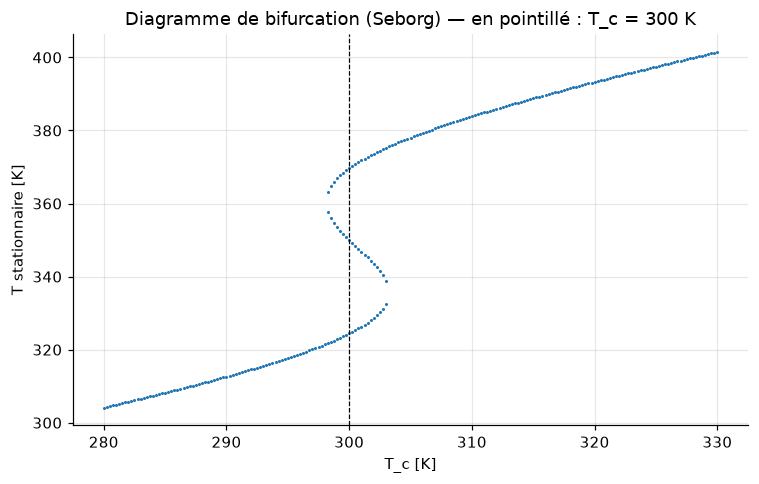

In [3]:
def n_states(p, Tc):
    return len(steady_states_level1(p.with_(Tc=Tc)))

def bifurcation_curve(p, Tcs):
    pts = []
    for Tc in Tcs:
        for ca, T in steady_states_level1(p.with_(Tc=Tc)):
            pts.append((Tc, T))
    return np.array(pts)

p = seborg().with_(level=1)
Tcs = np.linspace(280, 330, 201)
B = bifurcation_curve(p, Tcs)
counts = np.array([n_states(p, t) for t in Tcs])
# bornes de la zone de multiplicité
multi = Tcs[counts == 3]
print(f"Seborg : 3 états stationnaires pour T_c ∈ [{multi.min():.2f} ; {multi.max():.2f}] K")
print(f"  → T_c > {multi.max():.2f} K : seul l'état HAUT subsiste (l'état bas disparaît : allumage inévitable)")
print(f"  → T_c < {multi.min():.2f} K : seul l'état BAS subsiste (l'état haut disparaît : extinction inévitable)")
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(B[:, 0], B[:, 1], ".", ms=2)
ax.axvline(p.Tc, color="k", ls="--", lw=0.8)
ax.set(xlabel="T_c [K]", ylabel="T stationnaire [K]", title="Diagramme de bifurcation (Seborg) — en pointillé : T_c = 300 K")
fig.tight_layout()

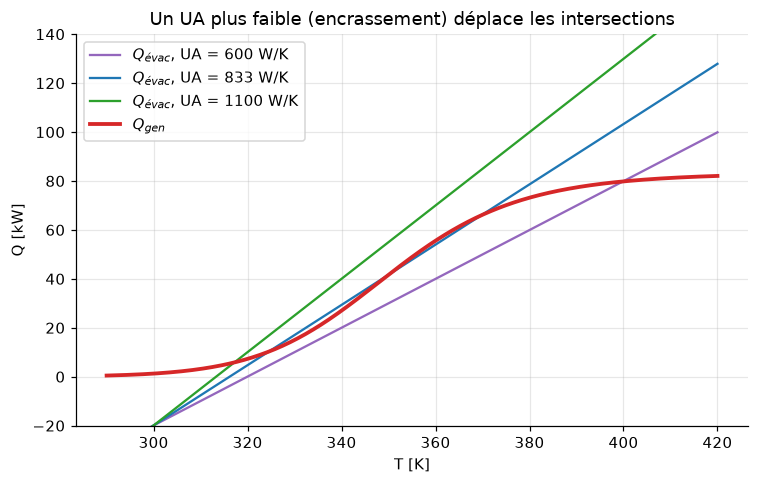

In [4]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for UA, c in [(600, "tab:purple"), (833.33, "tab:blue"), (1100, "tab:green")]:
    pp = p.with_(UAref=UA)
    Tg = np.linspace(290, 420, 400)
    ax.plot(Tg, [qrem(t, pp, UA=UA) / 1e3 for t in Tg], color=c, label=f"$Q_{{évac}}$, UA = {UA:.0f} W/K")
ax.plot(Tg, [qgen(t, p) / 1e3 for t in Tg], "tab:red", lw=2.5, label="$Q_{gen}$")
ax.set(xlabel="T [K]", ylabel="Q [kW]", ylim=(-20, 140), title="Un UA plus faible (encrassement) déplace les intersections")
ax.legend(); fig.tight_layout()

## S1-C04 — Dimensionnement de l'enveloppe (niveau 2)

Cahier des charges : au point nominal du benchmark ($T=350$ K, $T_j=300$ K) la chaleur à évacuer est $Q=UA\,(T-T_j)=41{,}7$ kW. À l'équilibre de l'enveloppe, avec la vanne à l'ouverture nominale $v_{nom}$ :

$$F_c=\frac{Q}{\rho_j C_{p,j}(T_j-T_{c,in})},\qquad F_{c,max}=\frac{F_c}{v_{nom}}$$

**Quelle conception retenir ?** Le point de fonctionnement est instable ; l'enveloppe ajoute un retard de l'ordre de $V_j/F_c$ et sa **capacité d'évacuation maximale** $UA\,(T-T_{c,in})$ borne la perturbation que *n'importe quel* régulateur peut rattraper. Pour chaque conception on calcule (i) la meilleure marge de stabilité linéaire (abscisse spectrale minimale en boucle fermée ; négative = stabilisable), (ii) le rapport capacité maximale / charge nominale et (iii) la **plus grande perturbation initiale rattrapée** en simulation non linéaire avec les meilleurs gains linéaires.

In [5]:
Q_nom = seborg().UAref * (350 - 300)
rows = []
designs = [("Plan (Vj=20 L, Tcin=285 K, v=0.5)", 20.0, 285.0, 0.5),
           ("Vj=10 L, Tcin=292 K, v=0.5", 10.0, 292.0, 0.5),
           ("Vj=5 L, Tcin=285 K, v=0.5", 5.0, 285.0, 0.5),
           ("RETENU : Vj=5 L, Tcin=278 K, v=0.3", 5.0, 278.0, 0.3)]
for name, Vj, Tcin, vnom in designs:
    Fc = Q_nom / (1000 * 4.18 * (300 - Tcin))
    p2 = seborg().with_(level=2, Vj=Vj, Tcin=Tcin, Fcmax=Fc / vnom)
    xs = steady_state_level2(p2, vnom, [0.5, 350.0, 300.0, vnom])
    A, B_ = linearize(p2, xs, vnom)
    best = search_gains(A, B_, tau_f=2.0, kp_range=(-2, 1.5), ki_range=(-5, -0.5), kd_values=(0, 3, 10), n=22)
    dT_max = max_recoverable_perturbation(p2, xs, vnom, best[1:])
    rows.append((name, Fc, Fc / vnom, Vj / Fc, best[0], UA_eff(p2) * (350 - Tcin) / Q_nom, dT_max))
pd.DataFrame(rows, columns=["conception", "F_c nominal [L/s]", "F_c,max [L/s]", "τ enveloppe V_j/F_c [s]",
                            "abscisse spectrale min [1/s]", "capacité max / nominal", "ΔT max rattrapable [K]"]).round(3)

,conception,F_c nominal [L/s],"F_c,max [L/s]",τ enveloppe V_j/F_c [s],abscisse spectrale min [1/s],capacité max / nominal,ΔT max rattrapable [K]
0,"Plan (Vj=20 L, Tcin=285 K, v=0.5)",0.665,1.329,30.096,-0.033,1.30,7.500
1,"Vj=10 L, Tcin=292 K, v=0.5",1.246,2.492,8.026,-0.033,1.16,4.125
2,"Vj=5 L, Tcin=285 K, v=0.5",0.665,1.329,7.524,-0.033,1.30,7.125
3,"RETENU : Vj=5 L, Tcin=278 K, v=0.3",0.453,1.510,11.035,-0.033,1.44,12.000


**Conclusion S1-C04.** Les quatre conceptions sont stabilisables par un PID avec une marge linéaire quasi identique (≈ −0,033 s⁻¹) : **le jeu du plan est pilotable**. Ce qui les distingue est l'**autorité** : la conception retenue ($V_j=5$ L, eau glacée à 5 °C, $F_{c,max}=1{,}510$ L/s, vanne nominale 30 %) offre 44 % de capacité d'évacuation au-delà du nominal (contre 30 % pour le plan) et rattrape les plus grosses perturbations (≥ 12 K contre ≈ 7,5 K pour le plan, ≈ 4 K pour $V_j=10$ L / $T_{c,in}=292$ K). Elle garde aussi 70 % de course de vanne en réserve vers l'ouverture. Valeurs dans `presets/seborgBenchmark.ts`.

> Limite physique à retenir : même vanne grande ouverte, $Q_{max}\approx UA\,(T-T_{c,in})$. Au-delà d'une certaine perturbation du point instable, aucun régulateur ne peut rattraper le réacteur — d'où l'intérêt du quench.

In [6]:
p2 = seborg().with_(level=2)
print(f"Fc,max retenu = {p2.Fcmax:.4f} L/s ;  Fc nominal = {Q_nom / (1000*4.18*(300-278)):.4f} L/s ; vérification dérivées nulles :")
print(np.round(rhs([0.5, 350.0, 300.0, 0.3], p2, Inputs(valve_cmd=0.3)), 6))
print(f"Capacité d'évacuation max (v=1, Tj→Tcin) ≈ {UA_eff(p2) * (350 - 278) / 1e3:.1f} kW  vs nominal {Q_nom / 1e3:.1f} kW")

Fc,max retenu = 1.5103 L/s ;  Fc nominal = 0.4531 L/s ; vérification dérivées nulles :
[ 1.0e-06 -3.8e-05  2.4e-05  0.0e+00]
Capacité d'évacuation max (v=1, Tj→Tcin) ≈ 60.0 kW  vs nominal 41.7 kW
